# Dispatch-down: checking the per-unit data

A first look at SEMO's per-unit balancing reports, collected by `isem-data`: what each unit was told to do (`dispatch_instructions`), what it could have produced (`availability`), what it did produce (`metered`), and who owns it (`units`).

*Dispatch-down* is wind or solar output the grid operator (EirGrid) told a farm not to produce: a **constraint** when the local grid can't carry the power, a **curtailment** when there is too much wind for the whole island.

The questions:

1. Which units are wind farms?
2. What units are the numbers in?
3. Do the wind farms add up to EirGrid's island total?
4. Does availability track output when a farm is left alone?
5. How much was dispatched down, and why?
6. Does that match outside figures?
7. Which farms lose most?

Run `python -m isem_data --datasets dispatch_instructions availability metered units wind --start 2026-08-07` first so `data/` has the files.

SEMO has no files at all for 27 October 2026, so that day is a gap in every chart below.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from isem_data import dispatch_down, storage

# One colour per series, always in this order (a colour-blind-safe palette).
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"

plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "figure.dpi": 90,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": MUTED,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "lines.linewidth": 1.5,
        "legend.frameon": False,
    }
)
pd.set_option("display.precision", 1)


def date_axis(ax):
    """Weekly ticks labelled like '07 Sep', so dates don't run into each other."""
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))


instructions = storage.load("dispatch_instructions")
availability = storage.load("availability")
metered = storage.load("metered")
units = storage.load("units")
wind = storage.load("wind")

for name, df in [
    ("instructions", instructions),
    ("availability", availability),
    ("metered", metered),
]:
    days = df["timestamp_utc"].dt.floor("D").unique()
    expected = pd.date_range(days.min(), days.max(), freq="D")
    missing = ", ".join(f"{day:%d %b}" for day in expected.difference(days))
    span = f"{days.min():%d %b} to {days.max():%d %b %Y}"
    print(f"{name:13} {span}, {len(df):,} rows; missing days: {missing or 'none'}")

instructions  06 Sep to 05 Nov 2026, 280,978 rows; missing days: 27 Oct
availability  06 Aug to 05 Nov 2026, 1,688,948 rows; missing days: 27 Oct
metered       06 Sep to 05 Nov 2026, 993,756 rows; missing days: 27 Oct


## 1. Which units are wind farms?

The unit list (`units`, SEMO report BM-091) gives each unit's fuel type. Solar farms appear to be listed as `WIND` too (SEMO has no solar fuel type), so "wind" here means wind and solar farms.

An earlier attempt used "units that received a `WIND` dispatch instruction". That finds only the farms that were actually cut, so it missed some.

In [2]:
wind_units = dispatch_down.wind_units(units)
instructed = set(instructions.query("instruction_code == 'WIND'")["unit"])

print(f"{len(wind_units)} units with fuel type WIND")
print(f"{len(instructed)} of them received a wind dispatch instruction in the period")
print(f"instructed units that are not WIND: {len(instructed - wind_units)}")
units.query("fuel_type == 'WIND'")["region"].value_counts()

229 units with fuel type WIND
196 of them received a wind dispatch instruction in the period
instructed units that are not WIND: 0


region
ROI    173
NI      56
Name: count, dtype: int64

## 2. What units are the numbers in?

SEMO calls the meter column `MeteredMW`, but it is **energy in the half-hour (MWh)**, not MW. Two ways to see it:

- a gas unit told to run at a steady 340 MW meters about 170 per half-hour;
- all generation plus imports comes to about half of EirGrid's demand.

So `metered_mwh * 2` is the average MW over the half-hour. Availability is already in MW.

In [3]:
# The instruction in force at the start of each half-hour, for half-hours when it was running.
gas = instructions.query("unit == 'GU_400930' and instruction_code == 'MWOF'")
gas = gas.sort_values("timestamp_utc")[["timestamp_utc", "instruction_mw"]]
gas_metered = metered.query("unit == 'GU_400930'").sort_values("timestamp_utc")
steady = pd.merge_asof(gas_metered, gas, on="timestamp_utc").dropna().query("instruction_mw > 0")
ratio = (steady["metered_mwh"] / steady["instruction_mw"]).median()
print(f"GU_400930: metered / instructed MW, median {ratio:.3f}")

demand = storage.load("demand").query("series == 'demand_actual_mw'")
demand = demand.set_index("timestamp_utc")["value"].resample("30min").mean()
supply = metered.query("unit_type in ['GEN', 'IU']").groupby("timestamp_utc")["metered_mwh"].sum()
both = pd.concat({"supply": supply, "demand": demand}, axis=1, sort=True).dropna()
print(f"(generation + imports) / demand, median {(both['supply'] / both['demand']).median():.3f}")

GU_400930: metered / instructed MW, median 0.498
(generation + imports) / demand, median 0.469


## 3. Do the wind farms add up to EirGrid's island total?

If the unit data is complete, summing every wind farm's output should come close to EirGrid's all-island `wind_actual_mw`. It can't match exactly: EirGrid's figure includes small farms that aren't registered as separate units in the market.

2,830 half-hours
farms / island energy: 0.947
correlation: 0.958
  Sep 2026: 0.981
  Oct 2026: 0.921
  Nov 2026: 0.965


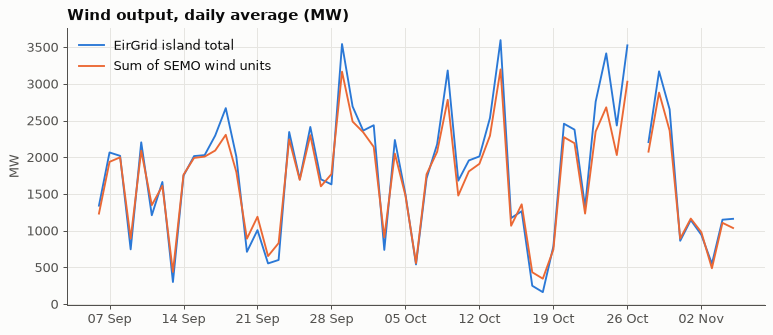

In [4]:
farms_mw = (
    metered[metered["unit"].isin(wind_units)].groupby("timestamp_utc")["metered_mwh"].sum() * 2
)
island_mw = (
    wind.query("series == 'wind_actual_mw'")
    .set_index("timestamp_utc")["value"]
    .resample("30min")
    .mean()
)
check = pd.concat({"farms": farms_mw, "island": island_mw}, axis=1, sort=True).dropna()

print(f"{len(check):,} half-hours")
print(f"farms / island energy: {check['farms'].sum() / check['island'].sum():.3f}")
print(f"correlation: {check['farms'].corr(check['island']):.3f}")
by_month = check["farms"].resample("MS").sum() / check["island"].resample("MS").sum()
for month_start, ratio in by_month.items():
    print(f"  {month_start:%b %Y}: {ratio:.3f}")

daily = check.resample("D").mean()
fig, ax = plt.subplots()
ax.plot(daily.index, daily["island"], color=BLUE, label="EirGrid island total")
ax.plot(daily.index, daily["farms"], color=ORANGE, label="Sum of SEMO wind units")
ax.set_title("Wind output, daily average (MW)")
date_axis(ax)
ax.set_ylabel("MW")
ax.legend(loc="upper left")
plt.show()

**Check 3 passes.** The registered wind units cover about 95% of EirGrid's island wind and move with it almost exactly. The missing 5% is most likely small farms that aren't separate market units.

## 4. Does availability track output when a farm is left alone?

Join each farm's availability and output by half-hour, and work out which instructions were in force.

A farm can be **constrained and curtailed at the same time**, so the two are tracked as separate switches: `LOCL` turns the constraint on and `LCLO` turns it off; `CURL` turns the curtailment on and `CRLO` turns it off. The switch's position in a half-hour is the last change before its middle. (A first version tracked one "current reason", so lifting a curtailment wrongly freed a farm that was still constrained. That flipped the constraint/curtailment split.)

The calculation lives in `isem_data/dispatch_down.py` (tested in `tests/test_dispatch_down.py`), so this notebook and anything else built on the data use the same method. `farm_half_hours` gives one row per farm and half-hour.

If availability is a good measure of "what the wind allowed", the gap between availability and output should be close to zero when neither switch is on.

In [5]:
farms = dispatch_down.farm_half_hours(availability, metered, instructions, units)
farms["gap_mw"] = farms["availability_mw"] - farms["output_mw"]

start = farms["timestamp_utc"].min()
print(f"{len(farms):,} farm half-hours, {farms['unit'].nunique()} farms, from {start:%d %b %Y}")
print(pd.crosstab(farms["constrained"], farms["curtailed"]))
farms.groupby("reason")["gap_mw"].describe()[["count", "mean", "25%", "50%", "75%"]]

609,412 farm half-hours, 217 farms, from 07 Sep 2026
curtailed     False  True 
constrained               
False        408326  88744
True          74443  37899


,count,mean,25%,50%,75%
reason,,,,,
constraint,112342.0,7.9,1.1,4.3,10.2
curtailment,88744.0,4.4,0.3,1.5,5.2
none,408326.0,0.4,0.0,0.1,0.5


**Mostly yes.** With no instruction in force the typical gap is about 0.1 MW, so availability tracks output. Over a whole period the uninstructed gap still adds up to several percent of availability (low-wind periods, outages, losses), but it isn't counted as dispatch-down because no instruction is in force.

## 5. How much was dispatched down, and why?

Dispatch-down for a farm in a half-hour is the gap between availability and output while an instruction is in force (negative gaps count as zero). Energy is MW × 0.5 h. `dispatch_down.totals` adds it up; its percentage is lost ÷ (produced + lost).

In [6]:
month = farms["timestamp_utc"].dt.tz_localize(None).dt.to_period("M")
print("By month (September starts on the 7th; November is only 5 days):")
display(farms.groupby(month).apply(dispatch_down.totals))
print("By region:")
display(farms.groupby("region").apply(dispatch_down.totals))
print("Whole period:")
dispatch_down.totals(farms)

By month (September starts on the 7th; November is only 5 days):


,produced_gwh,constraint_gwh,curtailment_gwh,dispatch_down_pct
timestamp_utc,,,,
2026-09,967.9,209.1,102.1,24.3
2026-10,1289.8,238.9,93.7,20.5
2026-11,112.9,0.6,0.4,0.9


By region:


,produced_gwh,constraint_gwh,curtailment_gwh,dispatch_down_pct
region,,,,
NI,431.8,147.3,10.9,26.8
ROI,1938.9,301.3,185.4,20.1


Whole period:


produced_gwh         2370.7
constraint_gwh        448.6
curtailment_gwh       196.2
dispatch_down_pct      21.4
dtype: float64

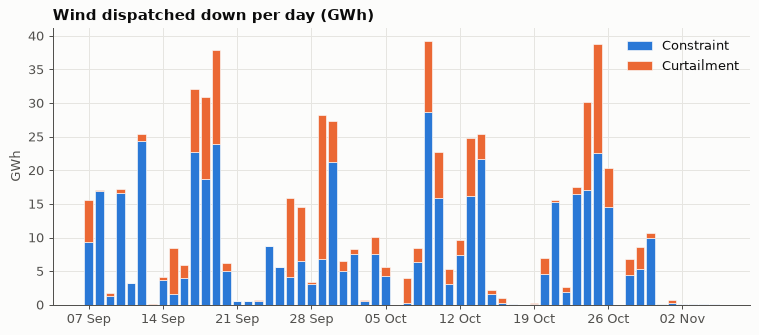

In [7]:
by_day = (
    farms.groupby([farms["timestamp_utc"].dt.floor("D"), "reason"])["lost_mwh"]
    .sum()
    .unstack(fill_value=0)
    / 1000
)

fig, ax = plt.subplots()
ax.bar(
    by_day.index,
    by_day["constraint"],
    width=0.8,
    color=BLUE,
    label="Constraint",
    edgecolor=SURFACE,
    linewidth=0.5,
)
ax.bar(
    by_day.index,
    by_day["curtailment"],
    width=0.8,
    bottom=by_day["constraint"],
    color=ORANGE,
    label="Curtailment",
    edgecolor=SURFACE,
    linewidth=0.5,
)
ax.set_title("Wind dispatched down per day (GWh)")
date_axis(ax)
ax.set_ylabel("GWh")
ax.legend(loc="upper right")
plt.show()

## 6. Does that match EirGrid's official figures?

EirGrid publishes a monthly dispatch-down workbook ([DD-Summary-Report-V23.xlsx](https://www.eirgrid.ie/sites/default/files/publications/DD-Summary-Report-V23.xlsx), through September 2026). Its September 2026 wind figures, typed in below:

| | Availability | Generation | Dispatch-down | Constraints | Curtailments |
|---|---|---|---|---|---|
| All-island | 1,647.2 GWh | 1,258.5 | 373.2 (22.7%) | 288.1 | 85.0 |
| Ireland | 1,295.4 | 1,017.9 | 265.4 (20.5%) | 194.3 | 71.0 |
| Northern Ireland | 351.9 | 240.6 | 107.8 (30.6%) | 93.8 | 14.0 |

EirGrid's percentage is dispatch-down ÷ availability. Our September only starts on the 7th (that's as far back as SEMO still had the instruction files), so compare percentages and shares, not GWh.

In [8]:
EIRGRID_SEP_2026 = pd.DataFrame(
    {
        "region": ["All-island", "Ireland", "Northern Ireland"],
        "availability": [1647.2, 1295.4, 351.9],
        "dispatch_down": [373.2, 265.4, 107.8],
        "constraints": [288.1, 194.3, 93.8],
    }
).set_index("region")

september = farms[farms["timestamp_utc"] < "2026-10-01"]
pieces = {
    "All-island": september,
    "Ireland": september[september["region"] == "ROI"],
    "Northern Ireland": september[september["region"] == "NI"],
}
rows = {}
for region, df in pieces.items():
    ours = dispatch_down.totals(df)
    lost = ours["constraint_gwh"] + ours["curtailment_gwh"]
    theirs = EIRGRID_SEP_2026.loc[region]
    rows[region] = {
        "ours: dispatch-down %": ours["dispatch_down_pct"],
        "EirGrid: dispatch-down %": 100 * theirs["dispatch_down"] / theirs["availability"],
        "ours: constraint share %": 100 * ours["constraint_gwh"] / lost,
        "EirGrid: constraint share %": 100 * theirs["constraints"] / theirs["dispatch_down"],
    }
pd.DataFrame(rows).T

,ours: dispatch-down %,EirGrid: dispatch-down %,ours: constraint share %,EirGrid: constraint share %
All-island,24.3,22.7,67.2,77.2
Ireland,22.4,20.5,58.4,73.2
Northern Ireland,31.5,30.6,91.0,87.0


**Close.** Our dispatch-down is within about 2 points of EirGrid's in every region, slightly high, and NI is far higher than Ireland in both. Our constraint share is lower than EirGrid's in Ireland. Likely reasons for the remaining gaps (not checked):

- EirGrid uses one-minute SCADA readings; we use half-hour averages and judge each half-hour by the instruction at its middle;
- EirGrid's own measure of available energy may differ slightly from SEMO's availability;
- our September misses its first six days.

An earlier comparison against a third-party newsletter's 13.1% for September, and against EirGrid's *annual* 13.4% for 2025, made our numbers look far too high. EirGrid's own monthly figures show windy autumn months regularly run near 20%.

## 7. Which farms lose most?

Unit codes are anonymous, but the company name on many farms is the wind farm's own supply company, so some names show through.

In [9]:
owners = units.set_index("unit")[["company", "region"]]
per_farm = farms.groupby("unit").agg(
    lost_gwh=("lost_mwh", lambda s: s.sum() / 1000),
    produced_gwh=("produced_mwh", lambda s: s.sum() / 1000),
    hours_held_down=("reason", lambda s: (s != "none").sum() / 2),
)
per_farm["dispatch-down %"] = (
    100 * per_farm["lost_gwh"] / (per_farm["lost_gwh"] + per_farm["produced_gwh"])
)
per_farm = per_farm.join(owners).sort_values("lost_gwh", ascending=False)

top10 = per_farm["lost_gwh"].head(10).sum() / per_farm["lost_gwh"].sum()
print(f"Top 10 farms' share of all dispatch-down: {top10:.0%}")
per_farm.head(15)

Top 10 farms' share of all dispatch-down: 22%


,lost_gwh,produced_gwh,hours_held_down,dispatch-down %,company,region
unit,,,,,,
GU_405140,17.8,30.0,660.5,37.2,Cloncreen Wind Farm Supply DAC,ROI
GU_406620,16.9,44.0,586.0,27.8,Derrinlough Wind Farm Supply DAC,ROI
GU_403760,16.9,47.3,704.0,26.4,ESB,ROI
GU_405130,15.1,47.8,716.0,24.1,Bord Gais Energy Limited,ROI
GU_401990,15.0,52.4,699.5,22.3,SSE Airtricity Limited,ROI
GU_401930,13.2,26.5,618.5,33.3,Energia Customer Solutions Limited,ROI
GU_405210,12.4,55.3,663.5,18.3,Lettermuckoo Energy Supply Limited,ROI
GU_501670,12.2,19.6,647.0,38.4,SSE Airtricity Energy Supply (NI) Limited,NI
GU_401690,12.0,26.5,623.0,31.2,Mount Lucas Supply Company Limited,ROI


## What this means

| Check | Result |
|---|---|
| Wind farms identified | 229 units with fuel type `WIND` (wind and probably solar) |
| Units | `metered` is MWh per half-hour; ×2 for MW. Availability is MW |
| Farms add up to the island | **Pass**: about 95% of EirGrid's island wind, correlation 0.96 |
| Availability when left alone | **Pass**: typical gap about 0.1 MW |
| Dispatch-down vs EirGrid, Sep 2026 | **Pass, roughly**: within about 2 points in every region; constraint share a bit low in Ireland |
| Missing data | 27 Oct 2026: no SEMO files for that day |

Public SEMO data reproduces EirGrid's official dispatch-down closely, **per farm and per half-hour**, about a month before EirGrid publishes its monthly figures.

**Next:**

1. Compare October once EirGrid publishes it (the next version of the workbook).
2. Find where the remaining constraint/curtailment difference comes from (look at farms with both switches on).
3. Split solar from wind (fuel type doesn't), probably by output at night.
4. Map more `GU_` codes to wind farm names.